# 04 — Semi-supervised learning with pseudo-labels

**Question:** if the fine-tuned Transformer labels the *artificial unlabeled pool* and we keep only its confident predictions, does training on labeled rows **plus** these pseudo-labeled rows beat training on labeled rows alone?

This notebook **reads saved results**. The only heavier part is the pool audit (section 2), which reads the saved probability files and takes about a minute; nothing is retrained.
Scripts: `src/predict_pseudo.py` (predict the pool), `src/make_pseudo_labels.py` (select), `src/finetune_transformer.py` (train), `src/evaluate_test.py` and `src/compare_test.py` (test and comparison).

**Provenance labels:** numbers *read from files* are computed when you run the cell; numbers marked *copied* come from earlier printed output and are not recomputed here.

## 1. Protocol (fixed before the experiment)

| step | rule |
|---|---|
| unlabeled pool | the 736,379 rows whose `recommendation_status` was hidden on purpose (the "artificial unlabeled" rows; their true labels are stored only for auditing) |
| pseudo-labeler | the supervised fine-tuned Transformer (`ft_200k`, selected checkpoint) predicts the recommendation status of every pool row |
| selection | accept a pseudo-label only if the **maximum probability is at least 0.90** (recommendation head only) |
| training | continue the same model from `ft_200k/best.pt` on labeled rows **plus** accepted pseudo rows; pseudo rows supervise **only the recommendation head** (their band target stays masked) |
| settings | same split, same preprocessing, same training settings, same number of steps as the control |
| comparison | the same validation and the same fixed test sample as all other models; test evaluated once per model |
| honesty rule | the hidden labels are used **only after the selection, for auditing**, never to choose which rows to accept |

Runs:

| name | what it is |
|---|---|
| `ft_200k` | the supervised Transformer (starting point, notebook 03) |
| `ctrl_200k` | **control**: continue `ft_200k` for the same number of steps on labeled rows only (isolates the effect of extra training from the effect of pseudo-labels) |
| `ssl_200k_v2` | **semi-supervised, main run**: labeled rows + pseudo rows, class weights from labeled rows only |
| `ssl_200k` | semi-supervised **v1**: class weights computed on labeled and pseudo rows combined. This was a **mistake in the first attempt** (the weights should come from labeled rows only). It is kept and reported as a sensitivity result, not hidden. |

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
REPORTS = ROOT / "reports"
TEST = REPORTS / "test_results"
INTERIM = ROOT / "data" / "interim"
PROBS = ROOT / "artifacts" / "ft_200k" / "pseudo_probs"
REC = ["no_idea", "not_recommended", "recommended"]
BAND = ["low", "medium", "high"]
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", None)

def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

HIST = {"supervised (ft_200k)": load_json(REPORTS / "ft_200k_history.json"),
        "control (ctrl_200k)": load_json(REPORTS / "ctrl_200k_history.json"),
        "semi-supervised v2 (ssl_200k_v2)": load_json(REPORTS / "ssl_200k_v2_history.json"),
        "semi-supervised v1 (ssl_200k)": load_json(REPORTS / "ssl_200k_history.json")}
MANIFEST = load_json(REPORTS / "pseudo_selection_manifest.json")
CMP = load_json(TEST / "comparison.json")
MODELS = {"transformer_supervised": "supervised", "transformer_control": "control",
          "transformer_ssl_v2": "semi-supervised v2", "transformer_ssl_v1_combined_weights": "semi-supervised v1 (combined weights)"}
TESTJ = {k: load_json(TEST / f"{k}.json") for k in MODELS}
print("project root:", ROOT)
print("histories:", {k: len(v["evals"]) for k, v in HIST.items()}, "evaluations each")

project root: /run/media/elahe/New Volume/maktab/145/digikala-review-classifier
histories: {'supervised (ft_200k)': 14, 'control (ctrl_200k)': 14, 'semi-supervised v2 (ssl_200k_v2)': 13, 'semi-supervised v1 (ssl_200k)': 13} evaluations each


## 2. Audit of the pseudo-label pool

The probabilities of the supervised model for all pool rows are stored in 15 parquet parts (`artifacts/ft_200k/pseudo_probs/`, not in git).
The true hidden labels (`data/interim/masked_ids.parquet`, not in git) are joined **only here, after the model has predicted**, to measure how good the pseudo-labels are.
If those two folders are missing on your machine, the next cells print a message and the notebook continues with the saved results below.

In [2]:
HAVE_POOL = PROBS.exists() and (INTERIM / "masked_ids.parquet").exists()
if HAVE_POOL:
    probs = pd.concat([pd.read_parquet(f) for f in sorted(PROBS.glob("part_*.parquet"))], ignore_index=True)
    print("rows:", len(probs), "| unique ids:", probs["id"].nunique())

    P = probs[[f"p_rec_{l}" for l in REC]].to_numpy()
    probs["pred"] = np.array(REC)[P.argmax(1)]
    probs["conf"] = P.max(1)

    ref = pd.read_parquet(INTERIM / "masked_ids.parquet")      # id, label (audit only)
    m = probs.merge(ref, on="id", how="left")
    print("rows without reference label:", m["label"].isna().sum())
    m["correct"] = m["pred"] == m["label"]

    print("\nreference class shares in the pool (%):")
    print((m["label"].value_counts(normalize=True) * 100).round(2).to_string())
else:
    print("pool files not found on this machine; skipping the audit cells (section 2).")

rows: 736379 | unique ids: 736379
rows without reference label: 0

reference class shares in the pool (%):
label
recommended        79.07
no_idea            11.31
not_recommended     9.63


In [3]:
if HAVE_POOL:
    rows = []
    for t in (0.70, 0.80, 0.90, 0.95):
        a = m[m["conf"] >= t]
        rows.append({"threshold": t, "accepted": len(a), "coverage_%": round(100 * len(a) / len(m), 1),
                     "accuracy_of_accepted_%": round(100 * a["correct"].mean(), 2),
                     **{f"accepted_{l}": int((a["pred"] == l).sum()) for l in REC}})
    print("Threshold table (the protocol uses 0.90; the others are for context only, nothing was retrained with them):")
    display(pd.DataFrame(rows).set_index("threshold"))

    a = m[m["conf"] >= 0.90]
    print("At threshold 0.90, per predicted class:")
    display(a.groupby("pred")["correct"].agg(accepted="size", precision="mean").round(4))

Threshold table (the protocol uses 0.90; the others are for context only, nothing was retrained with them):


,accepted,coverage_%,accuracy_of_accepted_%,accepted_no_idea,accepted_not_recommended,accepted_recommended
threshold,,,,,,
0.70,597354,81.1,92.39,25844,63596,507914
0.80,522490,71.0,95.08,6900,51333,464257
0.90,402492,54.7,97.28,128,34647,367717
0.95,299915,40.7,98.33,1,21999,277915


At threshold 0.90, per predicted class:


,accepted,precision
pred,,
no_idea,128,0.8438
not_recommended,34647,0.8660
recommended,367717,0.9829


In [4]:
if HAVE_POOL:
    rows = []
    for t in (0.70, 0.80, 0.90, 0.95):
        a = m[m["conf"] >= t]
        for l in REC:
            s = a[a["pred"] == l]
            rows.append({"threshold": t, "class": l, "accepted": len(s),
                         "precision_%": round(100 * s["correct"].mean(), 2) if len(s) else None})
    tab = pd.DataFrame(rows).pivot(index="class", columns="threshold", values=["accepted", "precision_%"])
    display(tab)

    wrong = m[(m["conf"] >= 0.90) & (~m["correct"])]
    print("wrong pseudo-labels at 0.90:", len(wrong), f"({len(wrong) / (m['conf'] >= 0.90).sum():.2%} of the accepted rows)")
    ct = pd.crosstab(wrong["pred"], wrong["label"], rownames=["predicted"], colnames=["true"])
    display(ct)
    print("share of the errors whose true label is no_idea: %.1f%%" % (100 * ct["no_idea"].sum() / ct.values.sum()))

accepted                               precision_%                      
threshold            0.70      0.80      0.90      0.95        0.70   0.80   0.90    0.95
class                                                                                    
no_idea           25844.0    6900.0     128.0       1.0       54.55  62.36  84.38  100.00
not_recommended   63596.0   51333.0   34647.0   21999.0       74.75  79.93  86.60   91.31
recommended      507914.0  464257.0  367717.0  277915.0       96.53  97.24  98.29   98.88

wrong pseudo-labels at 0.90: 10955 (2.72% of the accepted rows)


true,no_idea,not_recommended,recommended
predicted,,,
no_idea,0,6,14
not_recommended,3433,0,1209
recommended,5319,974,0


share of the errors whose true label is no_idea: 79.9%


**Reading the audit.** The accepted pseudo-labels are far from perfect and far from balanced: almost all accepted rows are predicted `recommended`, and `no_idea` is almost never accepted at 0.90 (the model is rarely that sure about it).
Most wrong pseudo-labels have the true label `no_idea`: these are reviews where the reviewer chose "no idea" although the text sounds positive or negative, so the pseudo-label teaches the model to ignore that signal.
A higher threshold gives cleaner pseudo-labels but fewer of them and an even stronger bias towards `recommended`. This trade-off is why the protocol fixed 0.90 in advance instead of tuning it on the test result.

## 3. The subset that was actually used for training

From the accepted rows, **200,000** were drawn at random so that the semi-supervised run has the same size as the labeled data (200,000 labeled + 200,000 pseudo rows, one epoch over the combination, 12,500 steps like the control).
The selection manifest saved by `make_pseudo_labels.py` is printed as it is:

In [5]:
print(json.dumps(MANIFEST, indent=2, ensure_ascii=False))

{
  "run_dir": "artifacts\\ft_200k",
  "threshold": 0.9,
  "max_rows": 200000,
  "seed": 2026,
  "pool_rows": 736379,
  "accepted_before_cap": 402492,
  "accepted_share_of_pool": 0.5466,
  "per_class_before_cap": {
    "no_idea": 128,
    "not_recommended": 34647,
    "recommended": 367717
  },
  "kept_rows": 200000,
  "per_class_kept": {
    "no_idea": 66,
    "not_recommended": 17125,
    "recommended": 182809
  },
  "mean_confidence_kept": 0.9629,
  "note": "selection uses model probabilities only; hidden labels were not read"
}


**Copied from earlier output (not recomputed):** the used subset has 66 `no_idea`, 17,125 `not_recommended` and 182,809 `recommended` pseudo-labels.
So the used pseudo-labels are about 91% `recommended` and only 0.03% `no_idea`: the semi-supervised run sees almost no extra `no_idea` examples, which is the hardest class (section 5 shows what happened to it).

## 4. Validation curves of the four runs

The runs after `ft_200k` start from its selected checkpoint, so their step counter starts again at 0; the curves are drawn on the same axis only to compare shapes, not to read "total steps".
Each evaluation uses the same 10,000-row validation sample.

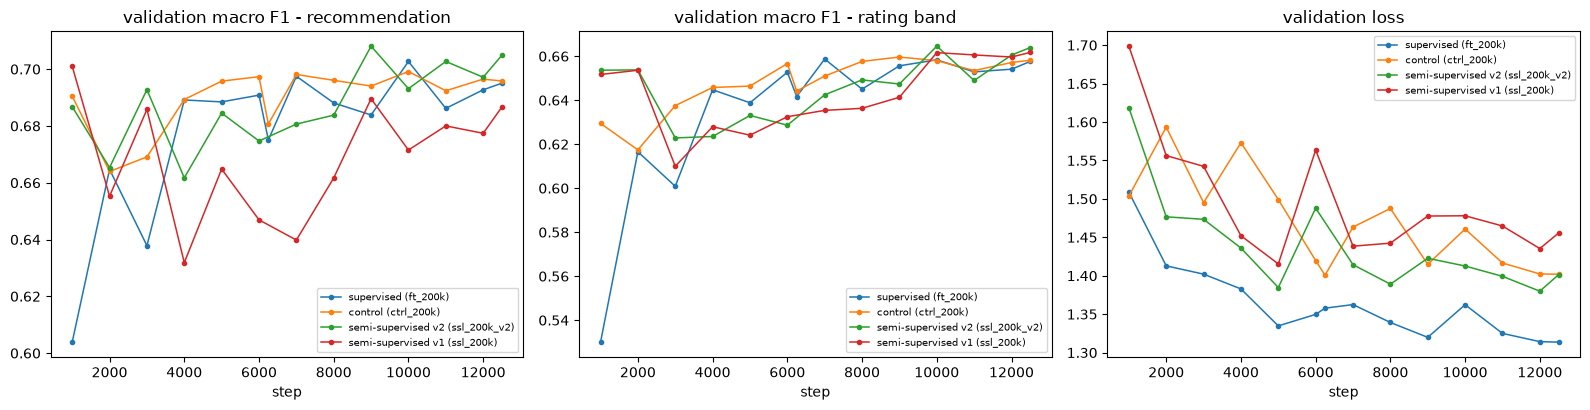

,evaluations,best step,best mean macro F1,rec macro F1 at best,band macro F1 at best,training minutes
run,,,,,,
supervised (ft_200k),14,10000,0.6805,0.7027,0.6584,237.83
control (ctrl_200k),14,10000,0.6786,0.6992,0.6580,236.53
semi-supervised v2 (ssl_200k_v2),13,12500,0.6844,0.7049,0.6639,251.55
semi-supervised v1 (ssl_200k),13,1000,0.6764,0.7010,0.6517,228.89


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for name, run in HIST.items():
    st = [e["step"] for e in run["evals"]]
    axes[0].plot(st, [e["rec"]["macro_f1"] for e in run["evals"]], "o-", lw=1.1, ms=3, label=name)
    axes[1].plot(st, [e["band"]["macro_f1"] for e in run["evals"]], "o-", lw=1.1, ms=3, label=name)
    axes[2].plot(st, [e["val_loss"] for e in run["evals"]], "o-", lw=1.1, ms=3, label=name)
axes[0].set_title("validation macro F1 - recommendation")
axes[1].set_title("validation macro F1 - rating band")
axes[2].set_title("validation loss")
for ax in axes:
    ax.set_xlabel("step"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

rows = []
for name, run in HIST.items():
    best = max(run["evals"], key=lambda e: e["mean_macro_f1"])
    rows.append({"run": name, "evaluations": len(run["evals"]), "best step": best["step"],
                 "best mean macro F1": best["mean_macro_f1"], "rec macro F1 at best": best["rec"]["macro_f1"],
                 "band macro F1 at best": best["band"]["macro_f1"], "training minutes": run["minutes"]})
display(pd.DataFrame(rows).set_index("run").round(4))

**Reading the curves.** Evaluations of the same run differ by about 0.01 from one step to the next, and the four runs lie within a few hundredths of each other.
Differences at the level of the noise between neighbouring evaluations are **not** evidence for or against the method; this is why the final decision is made on the large fixed test sample with paired bootstrap intervals (next section), not on these curves.

## 5. Final test comparison on the same fixed test sample

All four Transformer runs were scored **once** on the same random test sample (the same rows for every model). `n` is the number of rows with a valid target for that head.

In [7]:
def metrics_row(m):
    r = {"n": m["n"], "accuracy": m["accuracy"], "macro precision": m["macro_precision"],
         "macro recall": m["macro_recall"], "macro F1": m["macro_f1"], "balanced accuracy": m["balanced_accuracy"], "ECE": m["ece"]}
    if "ordinal_distance_error" in m:
        r["ordinal distance error"] = m["ordinal_distance_error"]
    return r

for head, label in (("rec", "recommendation"), ("band", "rating band")):
    tab = pd.DataFrame({MODELS[k]: metrics_row(TESTJ[k][head]) for k in MODELS}).T
    print(f"===== {label} (test) =====")
    display(tab.round(4))

===== recommendation (test) =====


,n,accuracy,macro precision,macro recall,macro F1,balanced accuracy,ECE
supervised,85279.0,0.8462,0.6672,0.7278,0.6933,0.7278,0.0280
control,85279.0,0.8416,0.6664,0.7245,0.6912,0.7245,0.0264
semi-supervised v2,85279.0,0.8319,0.6718,0.7377,0.6963,0.7377,0.0398
semi-supervised v1 (combined weights),85279.0,0.8376,0.6634,0.7214,0.6878,0.7214,0.0490


===== rating band (test) =====


,n,accuracy,macro precision,macro recall,macro F1,balanced accuracy,ECE,ordinal distance error
supervised,91578.0,0.7571,0.6399,0.6826,0.6584,0.6826,0.0630,0.2634
control,91578.0,0.7543,0.6388,0.6781,0.6560,0.6781,0.0505,0.2660
semi-supervised v2,91578.0,0.7540,0.6485,0.6825,0.6630,0.6825,0.0543,0.2644
semi-supervised v1 (combined weights),91578.0,0.7837,0.6547,0.6572,0.6518,0.6572,0.0231,0.2391


### Change in each required metric

Differences are **point differences** read from the table above. For macro F1, accuracy and balanced accuracy the bootstrap interval of the paired difference is also shown (from `comparison.json`); macro precision and macro recall have no stored interval, so no claim of significance is made for them.

In [8]:
PAIRS = [("transformer_ssl_v2", "transformer_supervised", "semi-supervised v2 minus supervised"),
         ("transformer_ssl_v2", "transformer_control", "semi-supervised v2 minus control"),
         ("transformer_control", "transformer_supervised", "control minus supervised"),
         ("transformer_ssl_v1_combined_weights", "transformer_control", "semi-supervised v1 minus control")]

def delta_table(head):
    rows = []
    for a_key, b_key, nice in PAIRS:
        A, B = TESTJ[a_key][head], TESTJ[b_key][head]
        pair = CMP["pairs"][head].get(f"{a_key} - {b_key}", {})
        row = {"comparison": nice}
        for metric, mname in (("accuracy", "accuracy"), ("macro_precision", "macro precision"), ("macro_recall", "macro recall"), ("macro_f1", "macro F1")):
            row[mname] = A[metric] - B[metric]
        for metric, mname in (("macro_f1", "macro F1"), ("accuracy", "accuracy")):
            if metric in pair:
                d, lo, hi = pair[metric][:3]
                row[f"{mname} 95% CI"] = f"[{lo:+.4f}, {hi:+.4f}]" + (" (excludes 0)" if (lo > 0 or hi < 0) else " (contains 0)")
        row["ECE"] = A["ece"] - B["ece"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("comparison")

for head, label in (("rec", "recommendation"), ("band", "rating band")):
    print(f"===== {label}: change in each metric (first model minus second) =====")
    t = delta_table(head)
    num = t.select_dtypes("number").columns
    display(t.style.format({c: "{:+.4f}" for c in num}))

===== recommendation: change in each metric (first model minus second) =====


,accuracy,macro precision,macro recall,macro F1,macro F1 95% CI,accuracy 95% CI,ECE
comparison,,,,,,,
semi-supervised v2 minus supervised,-0.0143,+0.0046,+0.0099,+0.0030,"[+0.0001, +0.0059] (excludes 0)","[-0.0159, -0.0128] (excludes 0)",+0.0119
semi-supervised v2 minus control,-0.0098,+0.0054,+0.0132,+0.0051,"[+0.0020, +0.0082] (excludes 0)","[-0.0114, -0.0082] (excludes 0)",+0.0134
control minus supervised,-0.0046,-0.0008,-0.0033,-0.0021,"[-0.0048, +0.0007] (contains 0)","[-0.0059, -0.0032] (excludes 0)",-0.0016
semi-supervised v1 minus control,-0.0040,-0.0030,-0.0031,-0.0034,"[-0.0068, +0.0000] (contains 0)","[-0.0057, -0.0023] (excludes 0)",+0.0226


===== rating band: change in each metric (first model minus second) =====


,accuracy,macro precision,macro recall,macro F1,macro F1 95% CI,accuracy 95% CI,ECE
comparison,,,,,,,
semi-supervised v2 minus supervised,-0.0030,+0.0086,-0.0001,+0.0046,"[+0.0025, +0.0066] (excludes 0)","[-0.0045, -0.0017] (excludes 0)",-0.0087
semi-supervised v2 minus control,-0.0003,+0.0097,+0.0044,+0.0071,"[+0.0046, +0.0094] (excludes 0)","[-0.0018, +0.0013] (contains 0)",+0.0038
control minus supervised,-0.0028,-0.0011,-0.0045,-0.0025,"[-0.0047, -0.0003] (excludes 0)","[-0.0043, -0.0013] (excludes 0)",-0.0125
semi-supervised v1 minus control,+0.0294,+0.0159,-0.0209,-0.0042,"[-0.0075, -0.0009] (excludes 0)","[+0.0274, +0.0316] (excludes 0)",-0.0274


### Per-class precision, recall and F1 (test)

The class `no_idea` is the one the pseudo-labels almost never help with (section 3), so look at its row first.

In [9]:
for head, labels, label in (("rec", REC, "recommendation"), ("band", BAND, "rating band")):
    parts = {}
    for k in ("transformer_supervised", "transformer_control", "transformer_ssl_v2"):
        parts[MODELS[k]] = pd.DataFrame(TESTJ[k][head]["per_class"]).T[["precision", "recall", "f1"]]
    both = pd.concat(parts, axis=1).reindex(labels)
    both[("", "support")] = pd.DataFrame(TESTJ["transformer_supervised"][head]["per_class"]).T["support"].astype(int)
    print(f"===== {label} (test) =====")
    display(both.round(3))

===== recommendation (test) =====


supervised                 control               semi-supervised v2                      
                 precision recall     f1 precision recall     f1          precision recall     f1 support
no_idea              0.409  0.477  0.441     0.399  0.507  0.447              0.378  0.579  0.457    9511
not_recommended      0.638  0.803  0.711     0.646  0.770  0.702              0.676  0.759  0.715    7922
recommended          0.954  0.903  0.928     0.954  0.897  0.925              0.961  0.876  0.917   67846

===== rating band (test) =====


supervised                 control               semi-supervised v2                      
        precision recall     f1 precision recall     f1          precision recall     f1 support
low         0.623  0.759  0.684     0.624  0.742  0.678              0.650  0.731  0.688    9022
medium      0.411  0.453  0.431     0.406  0.459  0.431              0.407  0.491  0.445   17031
high        0.886  0.836  0.860     0.886  0.833  0.858              0.888  0.826  0.856   65525

### Confusion matrices (test)

Row-normalised (share of each true class) with row counts.

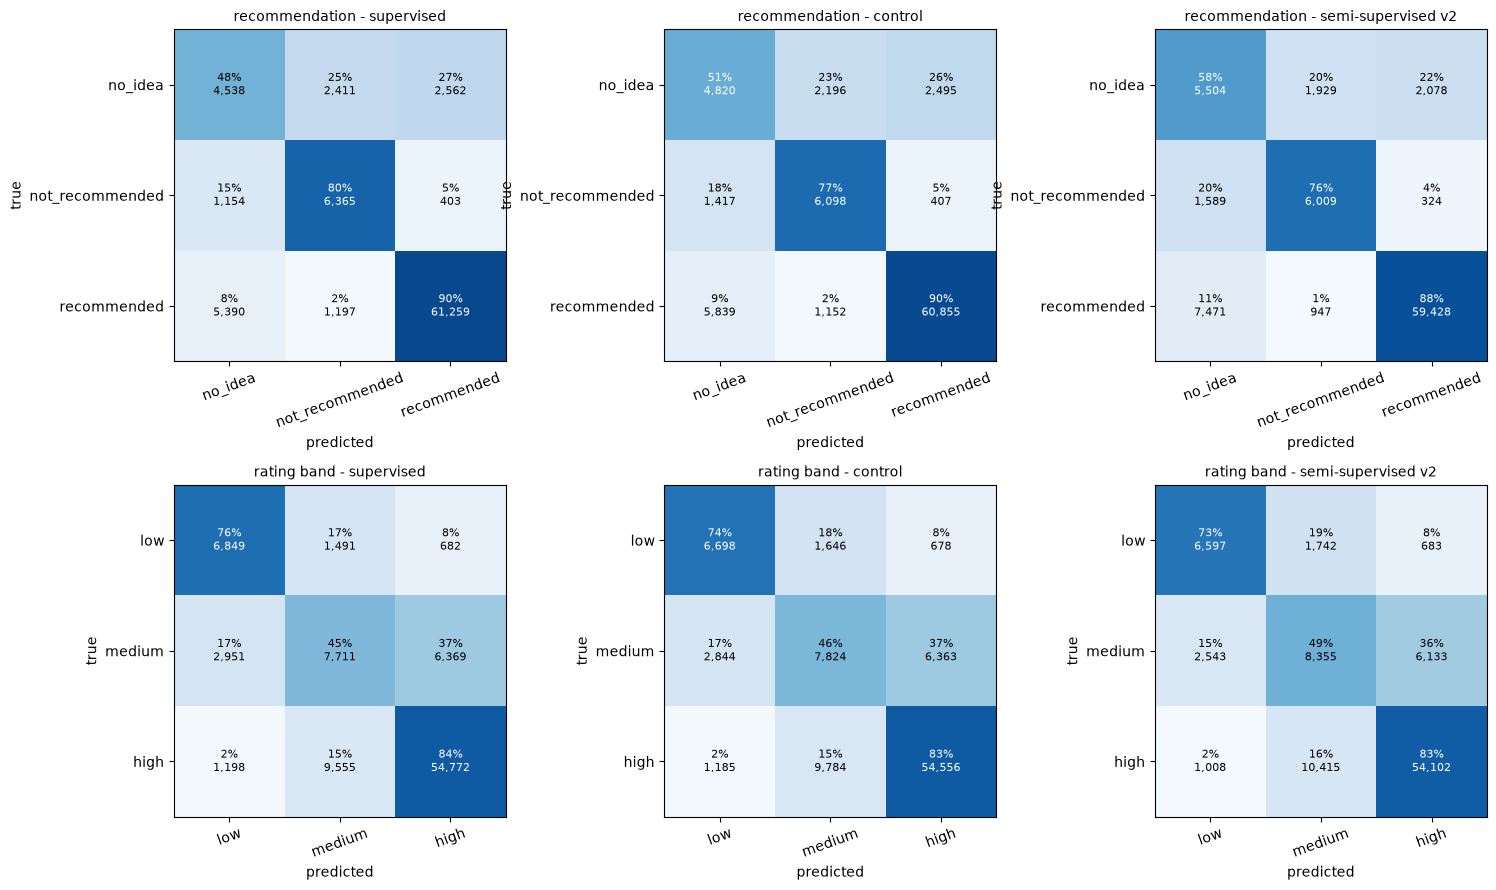

In [10]:
def plot_cm(ax, cm, labels, title):
    cm = np.array(cm, dtype=float)
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=20)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{share[i, j]:.0%}\n{int(cm[i, j]):,}", ha="center", va="center",
                    color="white" if share[i, j] > 0.5 else "black", fontsize=8)

keys = ("transformer_supervised", "transformer_control", "transformer_ssl_v2")
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, k in enumerate(keys):
    plot_cm(axes[0, j], TESTJ[k]["rec"]["confusion_matrix"], REC, f"recommendation - {MODELS[k]}")
    plot_cm(axes[1, j], TESTJ[k]["band"]["confusion_matrix"], BAND, f"rating band - {MODELS[k]}")
plt.tight_layout(); plt.show()

## 6. Conclusion

The lines below are generated from the saved comparison file, so they follow the numbers.

In [11]:
def line(head, a_key, b_key, nice):
    pair = CMP["pairs"][head][f"{a_key} - {b_key}"]
    out = [f"{nice} ({head}):"]
    for metric, mname in (("macro_f1", "macro F1"), ("accuracy", "accuracy"), ("balanced_accuracy", "balanced accuracy")):
        d, lo, hi = pair[metric][:3]
        verdict = "above 0" if lo > 0 else ("below 0" if hi < 0 else "contains 0")
        out.append(f"   {mname}: {d:+.4f} [{lo:+.4f}, {hi:+.4f}] -> interval {verdict}")
    print("\n".join(out))

for head in ("rec", "band"):
    line(head, "transformer_ssl_v2", "transformer_control", "semi-supervised v2 minus control")
    line(head, "transformer_ssl_v2", "transformer_supervised", "semi-supervised v2 minus supervised")
ece_c, ece_s = TESTJ["transformer_control"]["rec"]["ece"], TESTJ["transformer_ssl_v2"]["rec"]["ece"]
print(f"\nrecommendation ECE: control {ece_c:.4f} -> semi-supervised v2 {ece_s:.4f}")

semi-supervised v2 minus control (rec):
   macro F1: +0.0051 [+0.0020, +0.0082] -> interval above 0
   accuracy: -0.0098 [-0.0114, -0.0082] -> interval below 0
   balanced accuracy: +0.0132 [+0.0097, +0.0167] -> interval above 0
semi-supervised v2 minus supervised (rec):
   macro F1: +0.0030 [+0.0001, +0.0059] -> interval above 0
   accuracy: -0.0143 [-0.0159, -0.0128] -> interval below 0
   balanced accuracy: +0.0099 [+0.0067, +0.0129] -> interval above 0
semi-supervised v2 minus control (band):
   macro F1: +0.0071 [+0.0046, +0.0094] -> interval above 0
   accuracy: -0.0003 [-0.0018, +0.0013] -> interval contains 0
   balanced accuracy: +0.0044 [+0.0018, +0.0068] -> interval above 0
semi-supervised v2 minus supervised (band):
   macro F1: +0.0046 [+0.0025, +0.0066] -> interval above 0
   accuracy: -0.0030 [-0.0045, -0.0017] -> interval below 0
   balanced accuracy: -0.0001 [-0.0023, +0.0020] -> interval contains 0

recommendation ECE: control 0.0264 -> semi-supervised v2 0.0398


**Honest conclusion.**

* The **fair comparison is semi-supervised v2 against the control**, because both continue the same checkpoint for the same number of steps; the comparison with the original supervised model also mixes in the effect of simply training longer.
* The change in macro F1 of semi-supervised v2 over the control is **small** (a few thousandths); the bootstrap interval excludes 0, which means it is unlikely to be pure test-sampling noise. The **accuracy of the recommendation head goes down** and its calibration error goes up. So the gain is bought with a cost, and macro F1 alone would hide that.
* The gain is **not clearly robust**: there is one training run per model (no repeated seeds), and the differences between neighbouring validation evaluations (about 0.01, section 4) are larger than the gain itself. The bootstrap covers only the sampling of the test rows, not the randomness of training.
* A plausible reason for the limited benefit (a hypothesis, not tested here): the accepted pseudo-labels are about 91% `recommended` and almost contain no `no_idea`, and the model already predicts those rows with high confidence, so they add little new information while pushing the model towards the majority class.
* **Version 1 (combined class weights)** was a mistake of the first attempt; it is reported only as a sensitivity result. Its different behaviour on the band head (band accuracy and ordinal error changed, balanced accuracy of the recommendation head fell) shows that changing the weights of one head moved the other head through the shared encoder; that explanation is a hypothesis from one run.
* Final statement: **at most a small gain, not clearly robust, with a measurable cost in accuracy and calibration.** This does not show that semi-supervised learning cannot help; it shows what this specific protocol (threshold 0.90, 200,000 pseudo rows, one run) did.

## 7. Limitations

* One run per model; no repeated seeds; the bootstrap does not capture training randomness.
* Only one threshold (0.90) was used for training. The other thresholds in section 2 were audited, not trained.
* The pool is artificial: its labels were hidden from a labeled dataset, so it follows the same distribution as the labeled rows. A real unlabeled pool could differ.
* Pseudo-labels supervise only the recommendation head; the rating band target of those rows stays masked.
* The comparison with the original supervised model mixes the effect of pseudo-labels with the effect of extra training steps; the control run separates them.
* The test sample is a fixed random subset of the test split, the same rows for every model.